# Medical Imaging DICOM Project Notes

## Goal
Build a Python tool to load, visualize, process, and measure DICOM medical images.

## Tools Used
- Python
- pydicom
- NumPy
- Matplotlib
- scikit-image
- TCIA Data Retriever

## What is DICOM?
DICOM stands for Digital Imaging and Communications in Medicine. It stores medical image data and metadata.

## Current Progress
- Loaded pydicom sample CT image
- Displayed DICOM metadata
- Applied window/level adjustment
- Saved output image
- Started setting up TCIA dataset download

The Sample I am currently using can be found here: https://www.cancerimagingarchive.net/collection/fdg-pet-ct-lesions/

In here, I downloaded the defaced ones. The rest of the options make you download .csv files, which is generally just metadata which we do not want. The actual raw data should be .dcm.

When this was downloaded, it was actually in .tcia format. This is the entire manifest. Much more than we want. I also downloaded the TCIA Data Retriever but it kept opening as a blank page. Finally, I did not know what to do, so I used the following line

Then it gave me the following options:

Correct format is here:

Then I created a smaller manifest:

And then to check it, I used the 'cat' command:

There should be one long 1.3.6.... thing going in the last line. You want to download that series. Picture is shown.

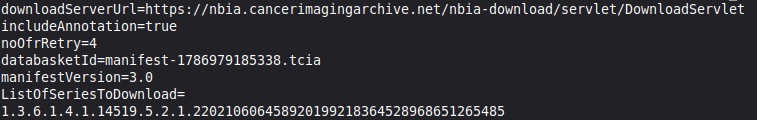

Essentially what this did is that it trimmed down the crazy excessive number of files we had, to just a few. A new directory was created called tcia_download_small.

Now we want to inspect whatever it is we downloaded

Now we want a list

You will find some crazy number of .dcm files. Screenshot attached:

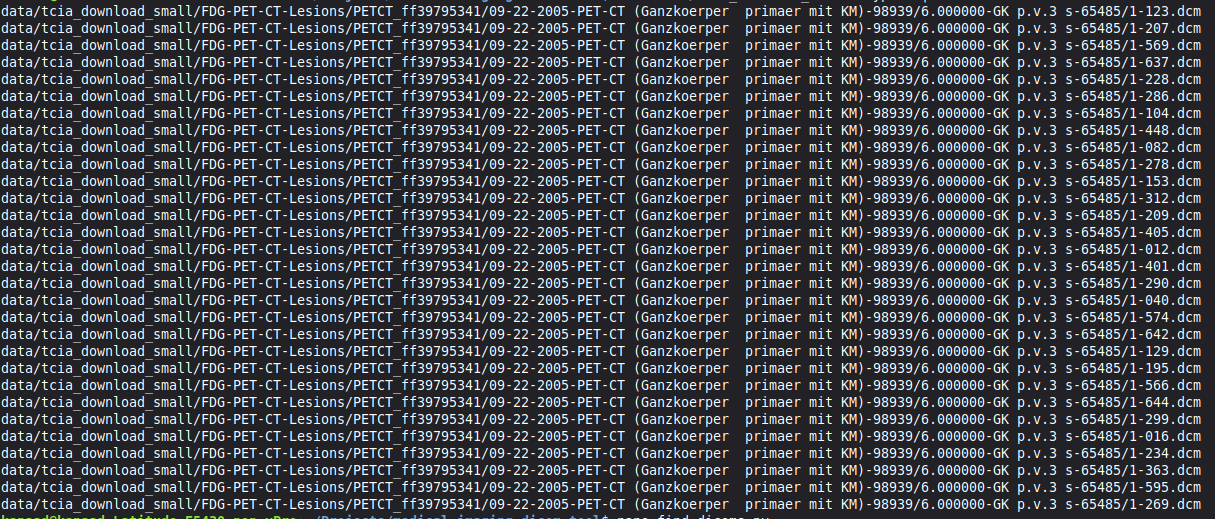

Those titles mean nothing to me. Here is a python script (find_dicoms.py) that will help us decipher each file listed:

In [5]:
import os
import pydicom

root_folder = "data/tcia_download_small"

count = 0

for root, dirs, files in os.walk(root_folder):
    for file in files:
        path = os.path.join(root, file)

        try:
            ds = pydicom.dcmread(path, stop_before_pixels=True, force=True)

            if "Modality" in ds:
                print("DICOM file:", path)
                print("  Modality:", ds.get("Modality", "N/A"))
                print("  Study Description:", ds.get("StudyDescription", "N/A"))
                print("  Series Description:", ds.get("SeriesDescription", "N/A"))
                print()
                count += 1

                if count >= 10:
                    break

        except Exception:
            pass

    if count >= 10:
        break

print(f"Found {count} DICOM-like files.")

Found 0 DICOM-like files.


To run it, send the following commands in terminal:

You should see something like the picture attached:

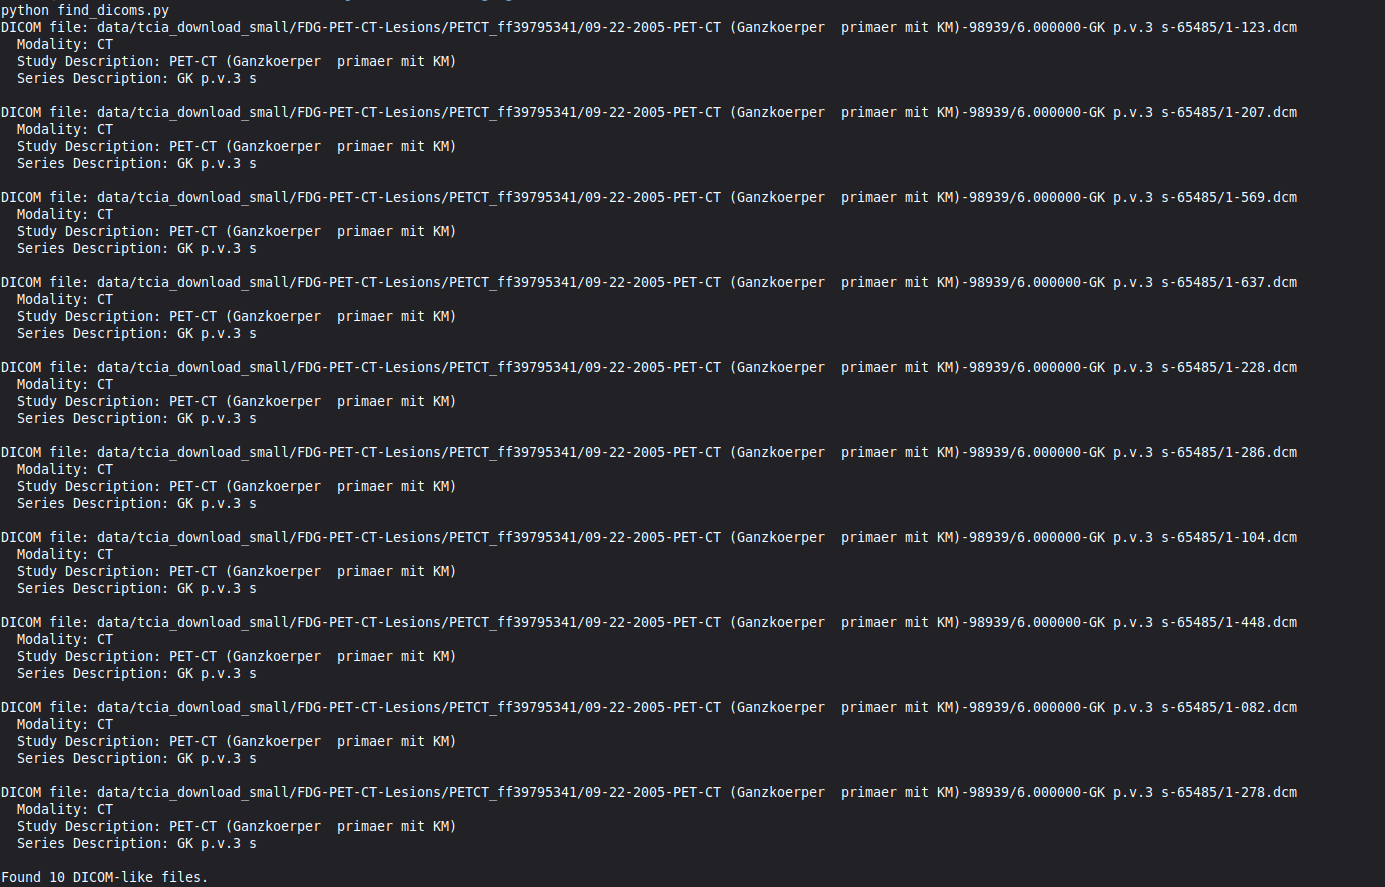

FIle paths of any of these is fair game. I picked the top most one. I pasted it in main.py, ran main.py, and got this in outputs:

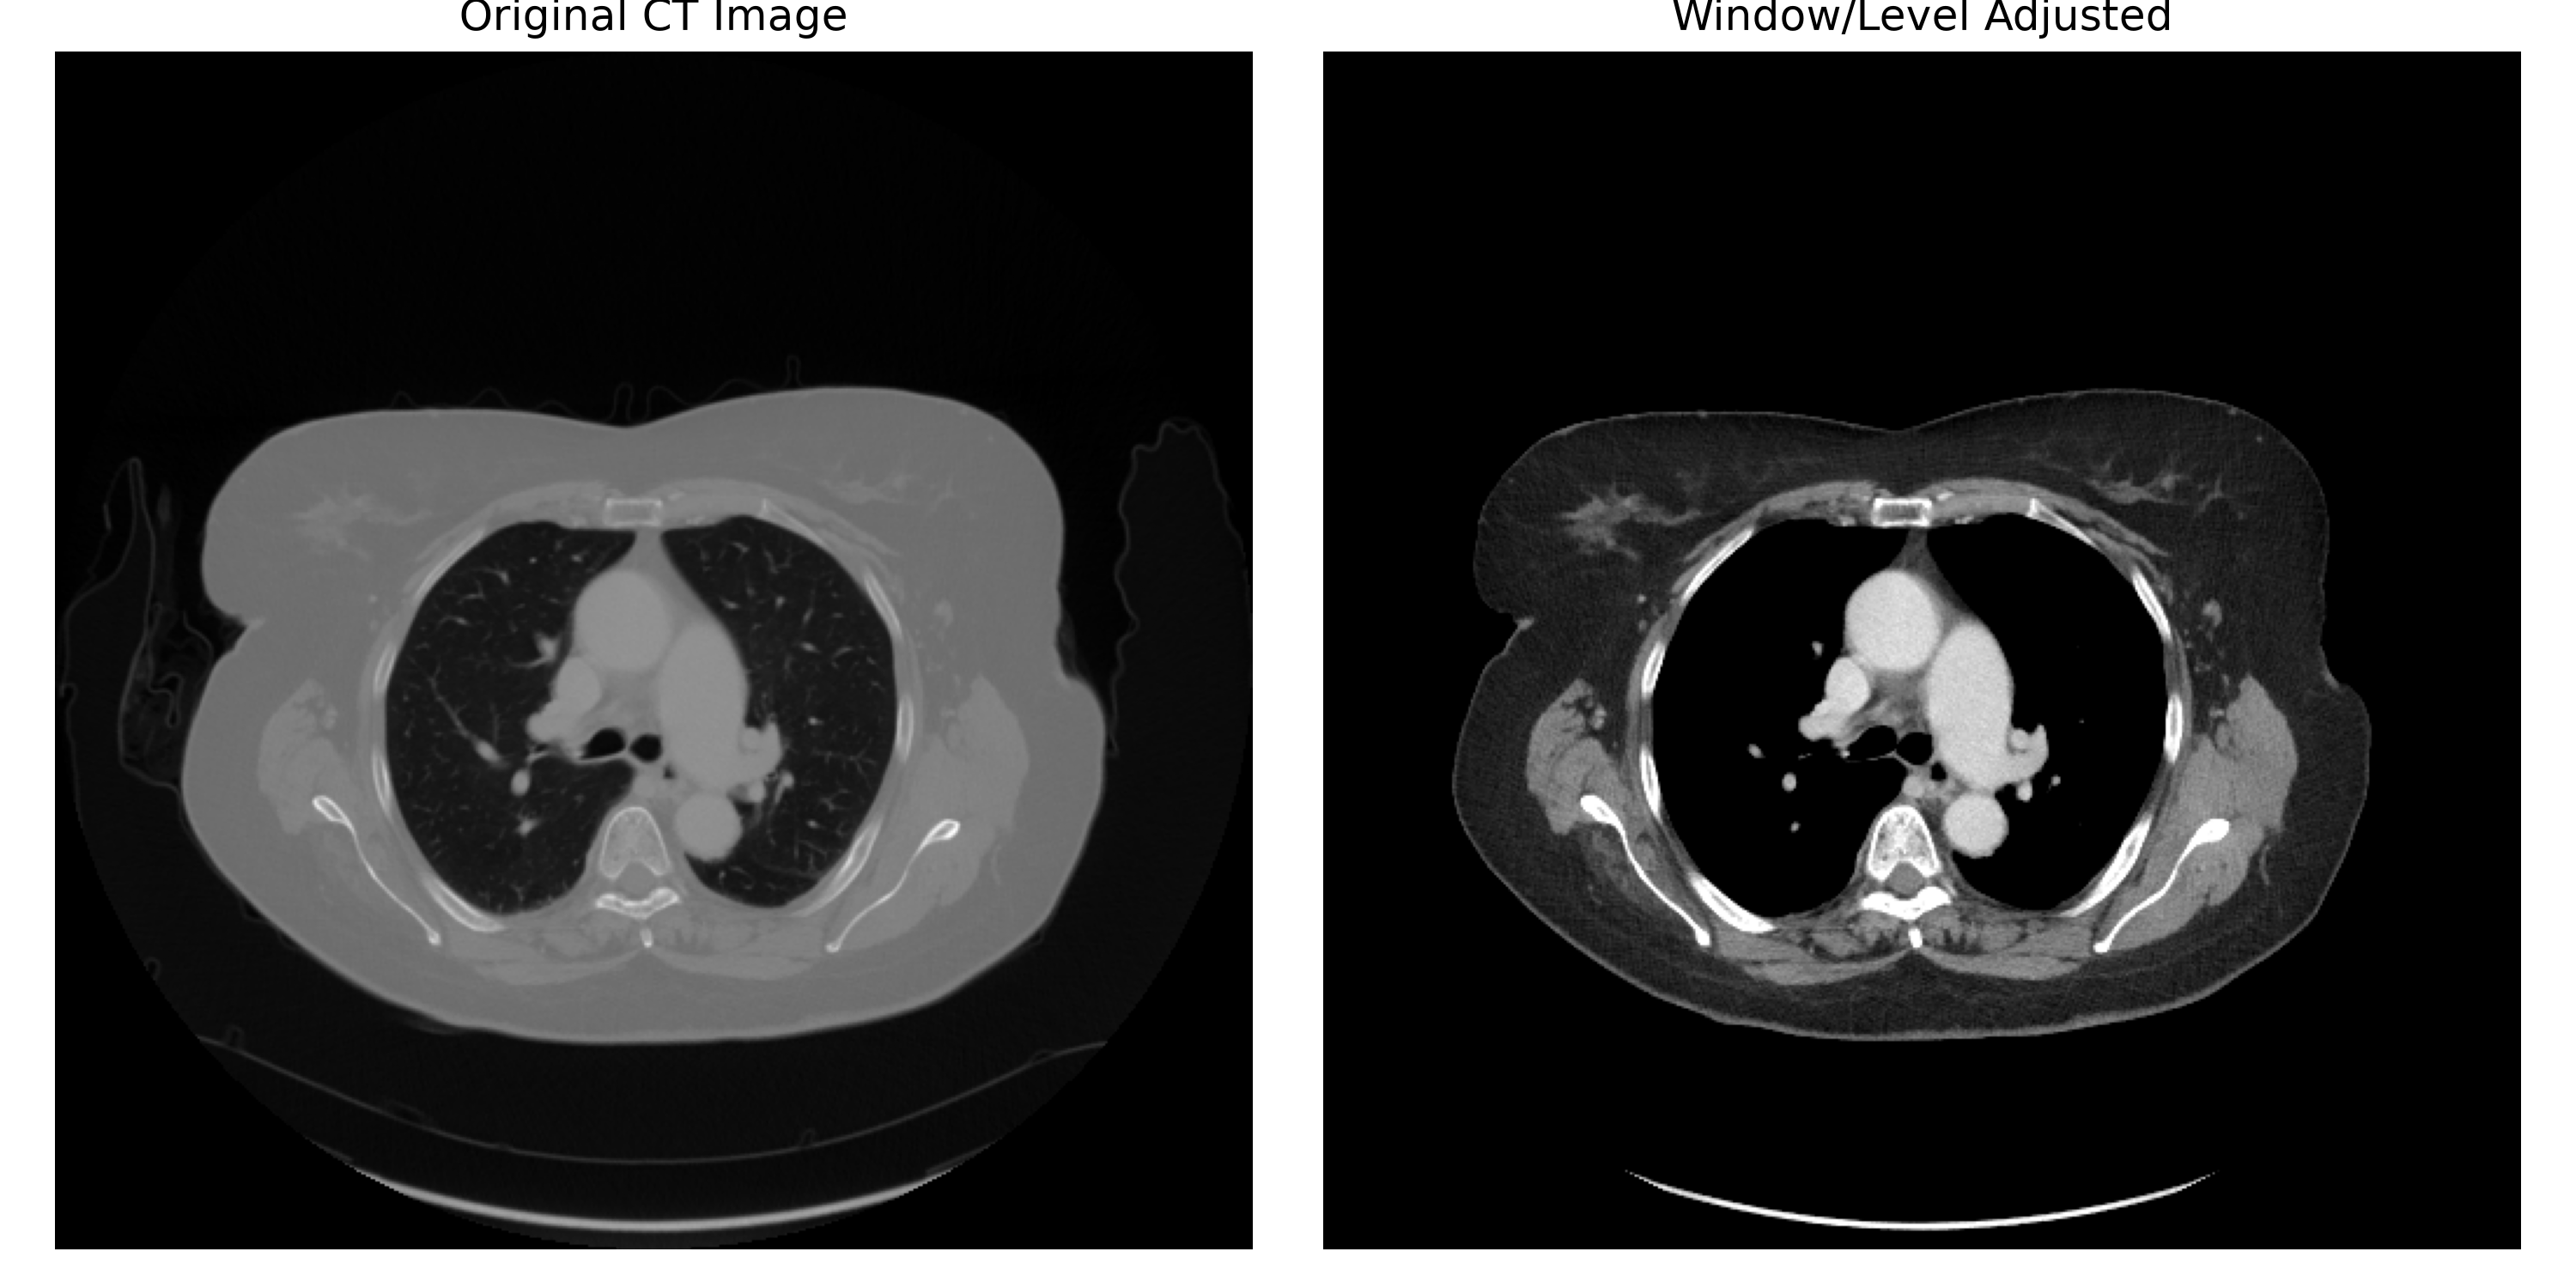

You will see this error:

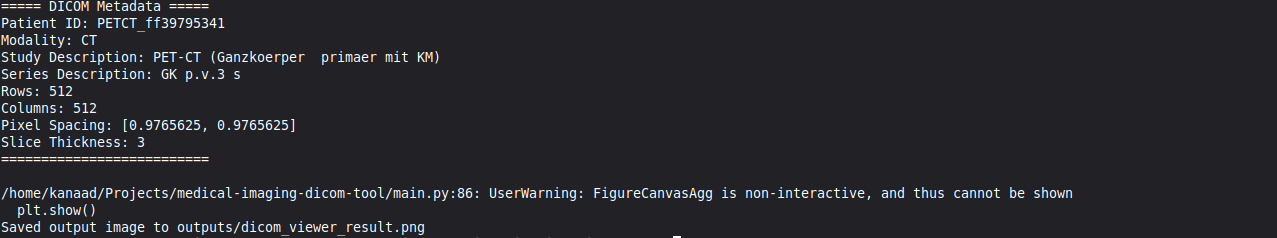

This simply means that the plt.show() line did not work, so a window does not open showing you the image. But the image will still be stored in the outputs folder. YOu need to run the following bash commands in terminal:

Then you need to replace the lines in which you import libraries, with these lines:

In [1]:
import pydicom
from pydicom.data import get_testdata_file
import numpy as np
import matplotlib
matplotlib.use("TkAgg")
import matplotlib.pyplot as plt
import os

`Agg` saves images to files. `TkAgg` saves png AND opens a window. WHen we saw the warning earlier it was using `Agg` already.

Another thing that we can change from previous code, we were just choosing a file and a file path and we were hardcoding that in our main() function. HOwever, we can change that. Here is the code at this point:

In [2]:
import pydicom
from pydicom.data import get_testdata_file
import numpy as np
import matplotlib
matplotlib.use("TkAgg")
import matplotlib.pyplot as plt
import os #os module lets python script interact with operating system. Itis needed if the code needs to 1) Create folders, 2) check if a file/folder exists, 3) list files in a folder, 4) gets the current working directory, or 5) works with file paths


def apply_window_level(image, window, level):
    """
    Apply CT-style window/level adjustment.
    """
    lower = level - window / 2
    upper = level + window / 2

    image_windowed = np.clip(image, lower, upper)
    image_windowed = (image_windowed - lower) / (upper - lower)
    image_windowed = image_windowed * 255

    return image_windowed.astype(np.uint8)


def get_image_pixels(ds):
    """
    Convert DICOM pixel data to float image.
    If CT data has RescaleSlope and RescaleIntercept,
    apply them to convert to Hounsfield Units.
    """
    image = ds.pixel_array.astype(np.float32)

    slope = float(ds.get("RescaleSlope", 1))
    intercept = float(ds.get("RescaleIntercept", 0))

    image = image * slope + intercept

    return image


def print_metadata(ds):
    """
    Print useful DICOM metadata.
    """
    print("===== DICOM Metadata =====")
    print("Patient ID:", ds.get("PatientID", "N/A"))
    print("Modality:", ds.get("Modality", "N/A"))
    print("Study Description:", ds.get("StudyDescription", "N/A"))
    print("Series Description:", ds.get("SeriesDescription", "N/A"))
    print("Rows:", ds.get("Rows", "N/A"))
    print("Columns:", ds.get("Columns", "N/A"))
    print("Pixel Spacing:", ds.get("PixelSpacing", "N/A"))
    print("Slice Thickness:", ds.get("SliceThickness", "N/A"))
    print("==========================\n")

def is_dicom_image(file_path):
    """
    Checks whether a file looks like a readable DICOM image
    FIlters out non image files like .tcia, .zip, etc
    """
    try:
        ds = pydicom.dcmread(file_path, stop_before_pixels=True, force=True)

        modality = ds.get("Modality", None)
        rows = ds.get("Rows", None)
        columns = ds.get("Columns", None)

        # Only keep files that look like actual image slices
        if modality in ["CT", "MR", "PT", "CR", "DX"] and rows is not None and columns is not None:
            return True

        return False

    except Exception:
        return False
        

def find_dicom_images(root_folder="data"):
    """
    Search the data folder for DICOM image files.
    """
    dicom_files = []

    if not os.path.exists(root_folder):
        return dicom_files

    for root, dirs, files in os.walk(root_folder):
        for file in files:
            file_path = os.path.join(root, file)

            if is_dicom_image(file_path):
                dicom_files.append(file_path)

    return dicom_files


def choose_dicom_path():
    """
    Let the user choose either the built-in pydicom sample
    or a local DICOM image from the data folder.
    """
    print("\nChoose DICOM source:")
    print("1. Use built-in pydicom sample")
    print("2. Choose local DICOM file from data/ folder")

    choice = input("Enter choice 1 or 2: ")

    if choice == "1":
        return get_testdata_file("CT_small.dcm")

    elif choice == "2":
        dicom_files = find_dicom_images("data")

        if len(dicom_files) == 0:
            print("\nNo local DICOM image files found in data/.")
            print("Using built-in pydicom sample instead.")
            return get_testdata_file("CT_small.dcm")

        print("\nFound DICOM image files:")

        for i, file_path in enumerate(dicom_files):
            print(f"{i + 1}. {file_path}")

        while True:
            try:
                selected = int(input("\nEnter file number to open: "))

                if 1 <= selected <= len(dicom_files):
                    return dicom_files[selected - 1]
                else:
                    print("Invalid number. Try again.")

            except ValueError:
                print("Please enter a valid number.")

    else:
        print("\nInvalid choice. Using built-in pydicom sample instead.")
        return get_testdata_file("CT_small.dcm")

def main():
    os.makedirs("outputs", exist_ok=True) #this is the line that required os, makedirs makes a directory

    # Use a built-in sample CT DICOM file from pydicom
    #dicom_path = get_testdata_file("CT_small.dcm")

    #Use hardcoded path
    #dicom_path = "/home/somefolder/anotherfolder/project/data/tcia_download_small/FDG-PET-CT-Lesions/PETCT_ff39795341/09-22-2005-PET-CT (Ganzkoerper  primaer mit KM)-98939/6.000000-GK p.v.3 s-65485/1-123.dcm"
    
    #Choose user-defined path
    dicom_path = choose_dicom_path()    
    ds = pydicom.dcmread(dicom_path)

    print_metadata(ds)

    image = get_image_pixels(ds)

    # Common soft tissue CT window (units are in HU)
    window = 400
    level = 40

    windowed_image = apply_window_level(image, window, level)

    plt.figure(figsize=(10, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(image, cmap="gray")
    plt.title("Original CT Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(windowed_image, cmap="gray")
    plt.title("Window/Level Adjusted")
    plt.axis("off")

    plt.tight_layout()
    plt.savefig("outputs/dicom_viewer_result.png", dpi=300)
    plt.show()

    print("Saved output image to outputs/dicom_viewer_result.png")


if __name__ == "__main__":
    main()


Choose DICOM source:
1. Use built-in pydicom sample
2. Choose local DICOM file from data/ folder


Enter choice 1 or 2:  1


===== DICOM Metadata =====
Patient ID: 1CT1
Modality: CT
Study Description: e+1
Series Description: N/A
Rows: 128
Columns: 128
Pixel Spacing: [0.661468, 0.661468]
Slice Thickness: 5.000000

Saved output image to outputs/dicom_viewer_result.png
